In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Load the dataset
california = fetch_california_housing(as_frame=True)
df = california.frame

# Extract feature (AveRooms) and target (MedHouseVal)
X = df[['AveRooms']].values
y = df['MedHouseVal'].values.reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=47)

print(f"Dataset Loaded successfully.")
print(f"Feature Matrix Shape (X): {X.shape}")
print(f"Target Vector Shape (y): {y.shape}\n")

print(f"Training Dataset Loaded successfully.")
print(f"Feature Matrix Shape (X): {X_train.shape}")
print(f"Target Vector Shape (y): {y_train.shape}\n")

print(f"Testing Dataset Loaded successfully.")
print(f"Feature Matrix Shape (X): {X_test.shape}")
print(f"Target Vector Shape (y): {y_test.shape}\n")

# Apply Standard Scaling
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
y_train_scaled = scaler_y.fit_transform(y_train)

X_test_scaled = scaler_X.transform(X_test)
y_test_scaled = scaler_y.transform(y_test)

m_train = len(y_train)

# Add a column of ones to X to handle the intercept/bias term (x_0 = 1)
X_b_train = np.c_[np.ones((m_train, 1)), X_train_scaled]
X_b_test = np.c_[np.ones((m_test, 1)), X_test_scaled]

Dataset Loaded successfully.
Feature Matrix Shape (X): (20640, 1)
Target Vector Shape (y): (20640, 1)

Training Dataset Loaded successfully.
Feature Matrix Shape (X): (16512, 1)
Target Vector Shape (y): (16512, 1)

Testing Dataset Loaded successfully.
Feature Matrix Shape (X): (4128, 1)
Target Vector Shape (y): (4128, 1)



In [ ]:
# --- APPROACH A: Normal Equation ---
theta_normal_scaled = np.linalg.inv(X_b_train.T.dot(X_b_train)).dot(X_b_train.T).dot(y_train_scaled)

# Generate and de-scale predictions for metrics evaluation
y_pred_normal_scaled = X_b_test.dot(theta_normal_scaled)
y_pred_normal = scaler_y.inverse_transform(y_pred_normal_scaled)


# --- APPROACH B: Batch Gradient Descent from Scratch ---
def compute_cost(X, y, theta):
    """Compute Mean Squared Error Cost."""
    m = len(y)
    predictions = X.dot(theta)
    cost = (1 / (2 * m)) * np.sum((predictions - y) ** 2)
    return cost

def gradient_descent(X, y, theta, learning_rate, iterations):
    """Perform batch gradient descent to learn theta."""
    m = len(y)
    cost_history = []

    for i in range(iterations):
        gradients = (1 / m) * X.T.dot(X.dot(theta) - y)
        theta = theta - learning_rate * gradients
        cost_history.append(compute_cost(X, y, theta))

    return theta, cost_history

# Initialize hyperparameters
learning_rate = 0.01
iterations = 1500
initial_theta = np.zeros((2, 1))

# Run optimization loop
theta_gd_scaled, cost_history = gradient_descent(X_b_train, y_train_scaled, initial_theta, learning_rate, iterations)

# Generate and de-scale predictions
y_pred_gd_scaled = X_b_test.dot(theta_gd_scaled)
y_pred_gd = scaler_y.inverse_transform(y_pred_gd_scaled)

In [ ]:
mse_normal = mean_squared_error(y_test, y_pred_normal)
r2_normal = r2_score(y_test, y_pred_normal)

mse_gd = mean_squared_error(y_test, y_pred_gd)
r2_gd = r2_score(y_test, y_pred_gd)

print("----- MODEL EVALUATION RESULTS -----")
print(f"Normal Equation:\n  - Mean Squared Error (MSE): {mse_normal:.4f}\n  - R-squared (R²):           {r2_normal:.4f}")
print(f"Gradient Descent:\n  - Mean Squared Error (MSE): {mse_gd:.4f}\n  - R-squared (R²):           {r2_gd:.4f}\n")
print(f"Final Weights (Scaled) - Normal Equation: Intercept = {theta_normal_scaled[0][0]:.4f}, Slope = {theta_normal_scaled[1][0]:.4f}")
print(f"Final Weights (Scaled) - Gradient Descent: Intercept = {theta_gd_scaled[0][0]:.4f}, Slope = {theta_gd_scaled[1][0]:.4f}")

----- MODEL EVALUATION RESULTS -----
Normal Equation:
  - Mean Squared Error (MSE): 1.3182
  - R-squared (R²):           0.0327
Gradient Descent:
  - Mean Squared Error (MSE): 1.3182
  - R-squared (R²):           0.0327

Final Weights (Scaled) - Normal Equation: Intercept = 0.0000, Slope = 0.1421
Final Weights (Scaled) - Gradient Descent: Intercept = 0.0000, Slope = 0.1421


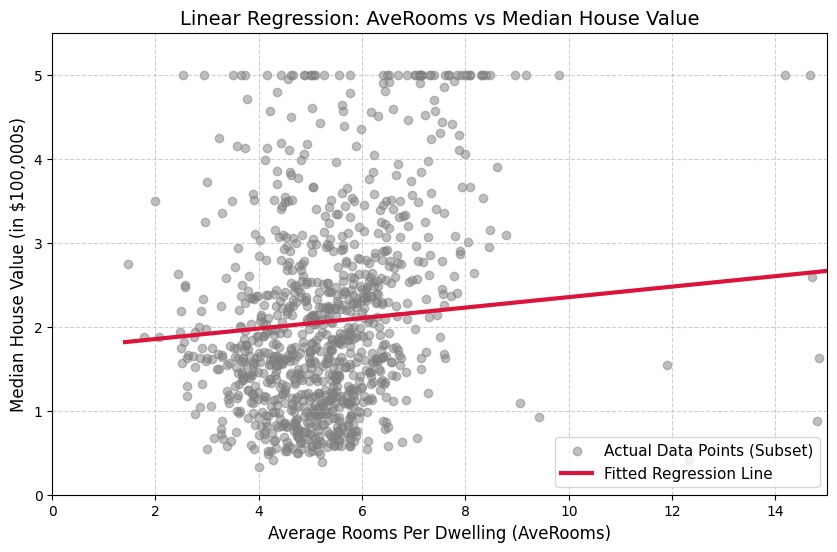

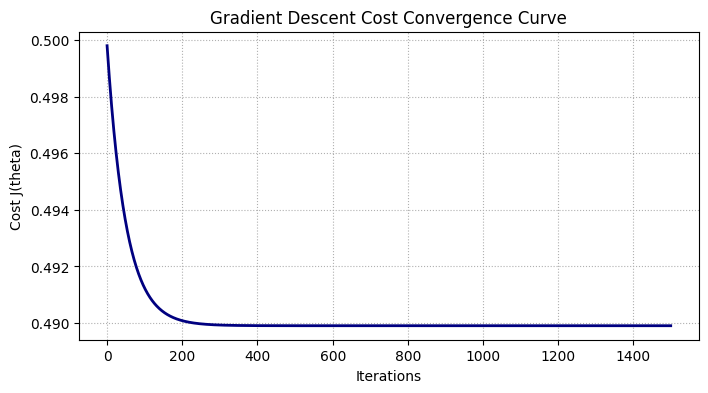

In [ ]:
sort_axis = np.argsort(X_test.flatten())
X_sorted = X_test[sort_axis]
y_pred_gd_sorted = y_pred_gd[sort_axis]

plt.figure(figsize=(10, 6))
plt.scatter(X_test[:1000], y_test[:1000], color='gray', alpha=0.5, label='Actual Data Points (Subset)')
plt.plot(X_sorted, y_pred_gd_sorted, color='crimson', linewidth=3, label='Fitted Regression Line')

plt.title('Linear Regression: AveRooms vs Median House Value', fontsize=14)
plt.xlabel('Average Rooms Per Dwelling (AveRooms)', fontsize=12)
plt.ylabel('Median House Value (in $100,000s)', fontsize=12)
plt.xlim(0, 15)
plt.ylim(0, 5.5)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Plot Convergence curve history
plt.figure(figsize=(8, 4))
plt.plot(range(iterations), cost_history, color='navy', linewidth=2)
plt.title('Gradient Descent Cost Convergence Curve')
plt.xlabel('Iterations')
plt.ylabel('Cost J(theta)')
plt.grid(True, linestyle=':')
plt.show()